In [1]:
import pandas as pd

# 1. Load the dataset (handling encoding for special characters)
df = pd.read_csv('superstore_sales.csv', encoding='latin1')

# 2. Data Wrangling: Convert 'Order Date' to datetime and create 'Year-Month' column
df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Year-Month'] = df['Order Date'].dt.to_period('M').astype(str)

# 3. Create Aggregated Summary Tables
print('=== 1. CATEGORY PERFORMANCE ===')
category_summary = df.groupby('Category')[['Sales', 'Profit']].sum().reset_index()
print(category_summary)
print('\n' + '='*40 + '\n')

print('=== 2. REGION PERFORMANCE ===')
region_summary = df.groupby('Region')[['Sales', 'Profit']].sum().reset_index()
print(region_summary)
print('\n' + '='*40 + '\n')

print('=== 3. CUSTOMER SEGMENT PERFORMANCE ===')
segment_summary = df.groupby('Segment')[['Sales', 'Profit']].sum().reset_index()
print(segment_summary)
print('\n' + '='*40 + '\n')

print('=== 4. MONTHLY SALES VELOCITY (TREND) ===')
monthly_sales = df.groupby('Year-Month')['Sales'].sum().reset_index()
print(monthly_sales.head(12)) # Showing first 12 months
print('\n' + '='*40 + '\n')

print('=== 5. DISCOUNT VS PROFIT ANALYSIS ===')
# Group by discount levels to see the threshold where profit turns negative
discount_summary = df.groupby('Discount')[['Profit']].mean().reset_index()
print(discount_summary.head(10))

# 4. Save the processed dataset with the new Year-Month column
df.to_csv('superstore_sales_processed.csv', index=False)
print('\nSuccessfully saved processed dataset as "superstore_sales_processed.csv"!')

=== 1. CATEGORY PERFORMANCE ===
          Category        Sales       Profit
0        Furniture  741999.7953   18451.2728
1  Office Supplies  719047.0320  122490.8008
2       Technology  836154.0330  145454.9481


=== 2. REGION PERFORMANCE ===
    Region        Sales       Profit
0  Central  501239.8908   39706.3625
1     East  678781.2400   91522.7800
2    South  391721.9050   46749.4303
3     West  725457.8245  108418.4489


=== 3. CUSTOMER SEGMENT PERFORMANCE ===
       Segment         Sales       Profit
0     Consumer  1.161401e+06  134119.2092
1    Corporate  7.061464e+05   91979.1340
2  Home Office  4.296531e+05   60298.6785


=== 4. MONTHLY SALES VELOCITY (TREND) ===
   Year-Month       Sales
0     2015-01  14236.8950
1     2015-02   4519.8920
2     2015-03  55691.0090
3     2015-04  28295.3450
4     2015-05  23648.2870
5     2015-06  34595.1276
6     2015-07  33946.3930
7     2015-08  27909.4685
8     2015-09  81777.3508
9     2015-10  31453.3930
10    2015-11  78628.7167
11   

<Axes: title={'center': 'Impact of Discount on Profit'}, xlabel='Discount', ylabel='Profit'>

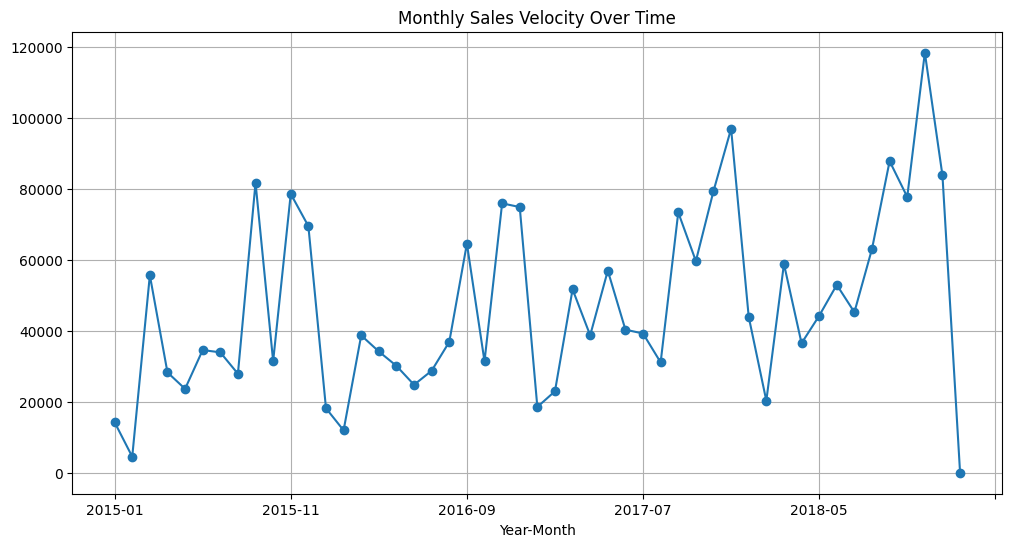

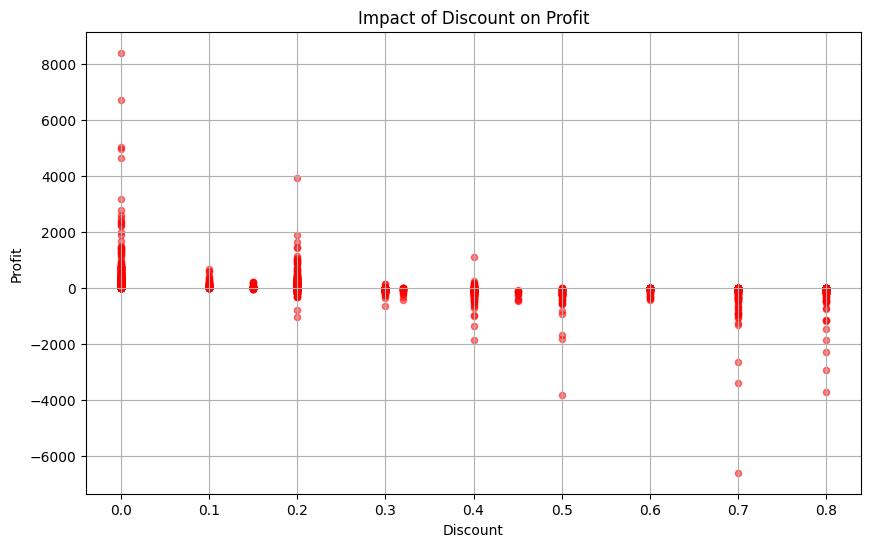

In [2]:
import pandas as pd

# 1. Load the dataset
df = pd.read_csv('superstore_sales.csv', encoding='latin1')

# 2. Data Wrangling: Create Year-Month column
df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Year-Month'] = df['Order Date'].dt.to_period('M').astype(str)

# --- CHART 1: Monthly Sales Velocity (Line Chart via Pandas) ---
monthly_sales = df.groupby('Year-Month')['Sales'].sum()
monthly_sales.plot(
    kind='line', 
    figsize=(12, 6), 
    title='Monthly Sales Velocity Over Time', 
    marker='o', 
    grid=True
)

# --- CHART 2: Discount vs. Profit (Scatter Plot via Pandas) ---
df.plot(
    kind='scatter', 
    x='Discount', 
    y='Profit', 
    figsize=(10, 6), 
    title='Impact of Discount on Profit', 
    alpha=0.5, 
    color='red', 
    grid=True
)

1. Category Profitability Discrepancies: While Technology and Office Supplies deliver robust net profits, Furniture generates high top-line sales but yields disproportionately low profits due to heavy discounting and high shipping costs.

2. The 20% Discount Threshold: Analyzing the discount vs. profit relationship reveals that discounts exceeding 20% consistently result in negative net profits (losses). Offering aggressive discounts past this threshold actively destroys business value.

3. Regional Sales Concentration: The West and East regions dominate total company revenue and profitability contributions, whereas the Central and South regions lag behind.

4. Customer Segment Dominance: The Consumer segment accounts for the vast majority of transaction volume and overall sales compared to Corporate and Home Office clients.

5. Sales Seasonality & Velocity: Monthly sales extracted via Year-Month exhibit major peaks towards the end of the year (Q4 / holiday season), signaling a strong need for seasonal inventory planning and logistics scaling.